In [1]:
from os import path

import mne_bids
import numpy as np
from mne.parallel import parallel_func

import mvEEG.mvEEG as mvEEG

from tqdm.notebook import tqdm
import argparse

import pandas as pd
import pingouin as pg
from collections import defaultdict

from scipy.stats import scoreatpercentile
import seaborn as sns
import matplotlib.pyplot as plt

from mne.stats import permutation_cluster_1samp_test

from glob import glob

import json

import pymc as pm
import arviz as az

%load_ext autoreload
%autoreload 2

In [2]:
# TODO: figure out the best time windows for these analyses!

In [3]:
RUN_DESCRIPTION = "M1vsM3"
np.random.seed(42)
OVERWRITE = False

In [4]:
import json

with open("rejected_subs.json", "r") as f:
    rejected_subs = json.load(f)
rejected_subs

['19', '32', '33']

In [5]:
training_labels = RUN_DESCRIPTION.split("vs")
if "M" in training_labels[0]:
    task = "WM"
    main_conds = ["M0", "M1", "M2", "M3", "M4", "M6", "M8"]
    alt_conds = ["A0", "A1", "A2", "A3", "A4", "A6", "A8"]
else:
    task = "ATT"
    main_conds = ["A0", "A1", "A2", "A3", "A4", "A6", "A8"]
    alt_conds = ["M0", "M1", "M2", "M3", "M4", "M6", "M8"]

code_dict = {
    "A0": 10,
    "A1": 11,
    "A2": 12,
    "A3": 13,
    "A4": 14,
    "A6": 16,
    "A8": 18,
    "M0": 20,
    "M1": 21,
    "M2": 22,
    "M3": 23,
    "M4": 24,
    "M6": 26,
    "M8": 28,
}
conditions = list(code_dict.keys())

train_codes = [code_dict[cond] for cond in training_labels]

ROOT = "../data/derivatives"
DATA_DIR = ROOT
EXPERIMENT_NAME = "banyan2"
dropped_chans = {"eeg": ["TP9", "Fp1", "Fp2"], "eog": "ALL", "eyegaze": [], "pupil": [], "misc": "ALL"}
# EOG and EYE channels will be analyzed separately, to see if they drive decoding results
# EOG_CHANS = ["HEOG", "VEOG"]
EYE_CHANS = ["xpos_left", "xpos_right", "ypos_left", "ypos_right", "pupil_left", "pupil_right"]

SUB_IGNORE_CHANS = {}


wrangl = mvEEG.Wrangler(
    data_dir=DATA_DIR,
    experiment_name=EXPERIMENT_NAME,
    dropped_chans=dropped_chans,
    t_win=50,
    t_step=25,
    trim_timepoints=[-350, 1200],
    trial_bin_size=15,
    n_folds=2,  # NOTE: _not_ using wrangler n_folds here
)

delay_window = (wrangl.t > 300) & (
    wrangl.t < 1100
)  # time window to average distances over, only includes when probes could appear

In [6]:
interp = mvEEG.Interpreter(
    data_dir=ROOT,
    experiment_name=EXPERIMENT_NAME,
    descriptions=[RUN_DESCRIPTION],
    labels=[0, 1],
    trial_phases={"Stim": (0, 200)},
    key_set=["predsPerTrial", "predsPerTrialEYES", "times", "classifierConditions"]
)

preds_perTrial, preds_EYES_perTrial, times, conds = interp.dataset.get_data(
    None, keys=["predsPerTrial", "predsPerTrialEYES", "times", "classifierConditions"]
)

del interp  # free up memory, since we don't need it anymore

/Users/henryjones/Documents/research/banyan/Experiment 2/analyses/mvEEG/mvEEG/dataloader.py:101: UserWarning: Data files have inconsistent shapes: [[1000 1289   63]
 [1000 1331   63]
 [1000 1339   63]
 [1000 1364   63]
 [1000 1389   63]
 [1000 1434   63]
 [1000 1440   63]
 [1000 1450   63]
 [1000 1465   63]
 [1000 1470   63]
 [1000 1474   63]
 [1000 1492   63]
 [1000 1493   63]
 [1000 1495   63]
 [1000 1508   63]
 [1000 1511   63]
 [1000 1529   63]
 [1000 1531   63]
 [1000 1549   63]
 [1000 1567   63]
 [1000 1570   63]
 [1000 1574   63]
 [1000 1575   63]
 [1000 1580   63]
 [1000 1582   63]
 [1000 1587   63]
 [1000 1590   63]
 [1000 1595   63]
 [1000 1611   63]
 [1000 2202   63]]
  warnings.warn(f"Data files have inconsistent shapes: {shape}")
/Users/henryjones/Documents/research/banyan/Experiment 2/analyses/mvEEG/mvEEG/dataloader.py:101: UserWarning: Data files have inconsistent shapes: [[1289]
 [1331]
 [1339]
 [1364]
 [1389]
 [1434]
 [1440]
 [1450]
 [1465]
 [1470]
 [1474]
 [1492]
 [14

In [7]:
# mean across iterations
preds_perTrial_meaned = [p.mean(0) for p in preds_perTrial]
del preds_perTrial  # free up memory, since we don't need it anymore

In [8]:
preds_EYES_perTrial_meaned = [p.mean(0) for p in preds_EYES_perTrial]
del preds_EYES_perTrial  # free up memory, since we don't need it anymore

In [9]:
# rename for simplicity
preds_perTrial = preds_perTrial_meaned
preds_EYES_perTrial = preds_EYES_perTrial_meaned

# For each subject, build up their (roughly) delay period classification scores from EEG and Eyes

In [10]:
def rescale_conds(conds):
    # rescale conditions to be between 0 and 1, for better interpretability in modeling
    return (conds - conds.min()) / (conds.max() - conds.min())

In [11]:
eeg_window = delay_window
eye_window = (times > 700) & (times < 1100)
pupil_window = (times > 700) & (times < 1100)


preds_df = pd.DataFrame()
for isub in range(len(preds_perTrial)):
    sub_preds = preds_perTrial[isub]
    sub_preds_EYES = preds_EYES_perTrial[isub]
    sub_conds = conds[isub]
    cond_mask = np.isin(sub_conds, train_codes)
    # subset to training conditions only, since we're only interested in MI between conditions making up the contrast, for now,
    # average across iterations, and then across the delay period
    sub_preds = sub_preds[cond_mask][:, eeg_window].mean(1)
    sub_preds_EYES = sub_preds_EYES[cond_mask][:, eye_window].mean(1)
    sub_conds = sub_conds[cond_mask]

    sub_df = pd.DataFrame({"EEG": sub_preds, "EYE": sub_preds_EYES, "cond": rescale_conds(sub_conds)})
    sub_df["sub"] = isub
    preds_df = pd.concat([preds_df, sub_df], ignore_index=True)

preds_df["cond"] -= 0.5  # rescale conditions to be between -0.5 and 0.5, for better interpretability in modeling

# Bayesian Modeling

In [12]:
subjects = preds_df["sub"].unique()
preds_df

,EEG,EYE,cond,sub
0,0.480424,-0.250968,0.5,0
1,-0.104503,-0.263839,0.5,0
2,0.003182,0.721718,-0.5,0
3,0.127494,-0.137555,-0.5,0
4,0.231887,-0.080147,0.5,0
...,...,...,...,...
6655,0.300600,-0.137173,0.5,29
6656,-0.501567,-0.760429,-0.5,29
6657,-0.316835,-0.651368,-0.5,29
6658,-1.397319,-1.288037,-0.5,29


In [13]:
def build_model(preds_df, eye_col="EYE"):
    with pm.Model() as model:
        # multivele model predicting EEG from EYE and condition, with random intercepts for subjects

        # hyperpriors for group-level parameters
        mu_intercept = pm.Normal("mu_intercept", mu=0, sigma=1)
        sigma_intercept = pm.HalfNormal("sigma_intercept", sigma=1)
        mu_eye = pm.Normal("mu_eye", mu=0, sigma=1)
        sigma_eye = pm.HalfNormal("sigma_eye", sigma=1)
        mu_cond = pm.Normal("mu_cond", mu=0, sigma=1)
        sigma_cond = pm.HalfNormal("sigma_cond", sigma=1)

        sub_intercept = pm.Normal("sub_intercept", mu=0, sigma=1, shape=len(subjects))
        sub_eye = pm.Normal("sub_eye", mu=0, sigma=1, shape=len(subjects))
        sub_cond = pm.Normal("sub_cond", mu=0, sigma=1, shape=len(subjects))

        intercepts = pm.Deterministic("intercepts", mu_intercept + sub_intercept * sigma_intercept)
        eye_coeffs = pm.Deterministic("eye_coeffs", mu_eye + sub_eye * sigma_eye)
        cond_coeffs = pm.Deterministic("cond_coeffs", mu_cond + sub_cond * sigma_cond)

        mu = (
            intercepts[preds_df["sub"].values]
            + eye_coeffs[preds_df["sub"].values] * preds_df[eye_col].values
            + cond_coeffs[preds_df["sub"].values] * preds_df["cond"].values
        )
        sigma = pm.HalfNormal("sigma", sigma=1)
        EEG_obs = pm.Normal("EEG_obs", mu=mu, sigma=sigma, observed=preds_df["EEG"].values)

    return model

In [14]:
model = build_model(preds_df, eye_col="EYE")

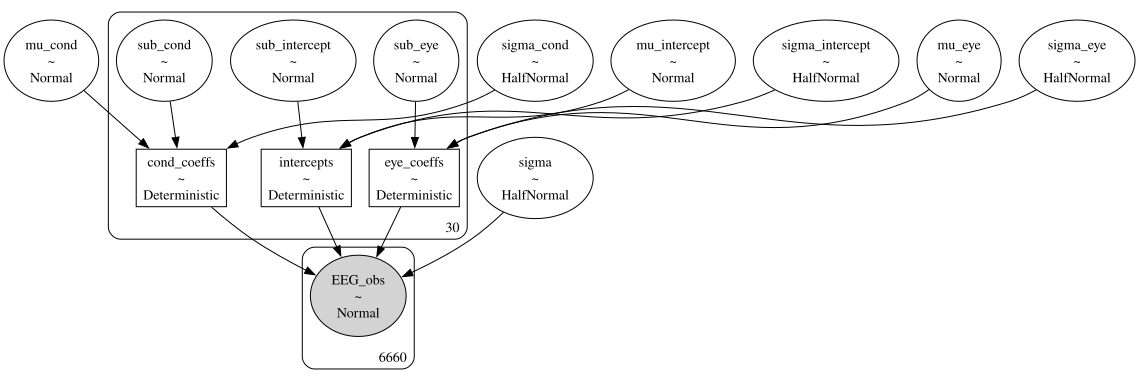

In [15]:
pm.model_to_graphviz(model)

In [16]:
with model:
    trace = pm.sample(
        5000,  # real samples per chain
        tune=4000,  # warmup samples per chain
        chains=4,
        random_seed=0,
        target_accept=0.95,
        return_inferencedata=True,
        idata_kwargs={"log_likelihood": True},
        nuts_sampler="numpyro",
    )
    trace.extend(pm.sample_prior_predictive(20_000))  # add prior predictive samples to the idata for later checks

  0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 0/9000 [00:00<?, ?it/s]

Sampling: [EEG_obs, mu_cond, mu_eye, mu_intercept, sigma, sigma_cond, sigma_eye, sigma_intercept, sub_cond, sub_eye, sub_intercept]


In [17]:
summary_table = az.summary(trace)
summary_table

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu_intercept,0.002,0.009,-0.015,0.019,0.000,0.000,33926.0,13881.0,1.0
mu_eye,0.005,0.014,-0.022,0.031,0.000,0.000,25741.0,15170.0,1.0
mu_cond,0.492,0.055,0.392,0.598,0.001,0.001,5239.0,8215.0,1.0
sub_intercept[0],0.022,0.992,-1.791,1.922,0.005,0.008,35979.0,14396.0,1.0
sub_intercept[1],0.025,0.984,-1.811,1.920,0.005,0.008,34583.0,14518.0,1.0
...,...,...,...,...,...,...,...,...,...
cond_coeffs[25],0.696,0.088,0.537,0.866,0.000,0.000,35932.0,14855.0,1.0
cond_coeffs[26],0.687,0.091,0.515,0.856,0.000,0.000,36192.0,14214.0,1.0
cond_coeffs[27],0.400,0.088,0.230,0.562,0.000,0.000,35790.0,14440.0,1.0
cond_coeffs[28],0.677,0.089,0.513,0.844,0.000,0.000,35404.0,14947.0,1.0


In [18]:
# for interpreted parameters
summary_table.loc[["mu_eye", "mu_cond"]]

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu_eye,0.005,0.014,-0.022,0.031,0.000,0.000,25741.0,15170.0,1.0
mu_cond,0.492,0.055,0.392,0.598,0.001,0.001,5239.0,8215.0,1.0


In [19]:
summary_table.ess_bulk.describe()

count      187.000000
mean     28377.572193
std       8691.115074
min       5239.000000
25%      25050.000000
50%      30301.000000
75%      35107.000000
max      40669.000000
Name: ess_bulk, dtype: float64

In [20]:
summary_table.r_hat.describe()

count    187.0
mean       1.0
std        0.0
min        1.0
25%        1.0
50%        1.0
75%        1.0
max        1.0
Name: r_hat, dtype: float64

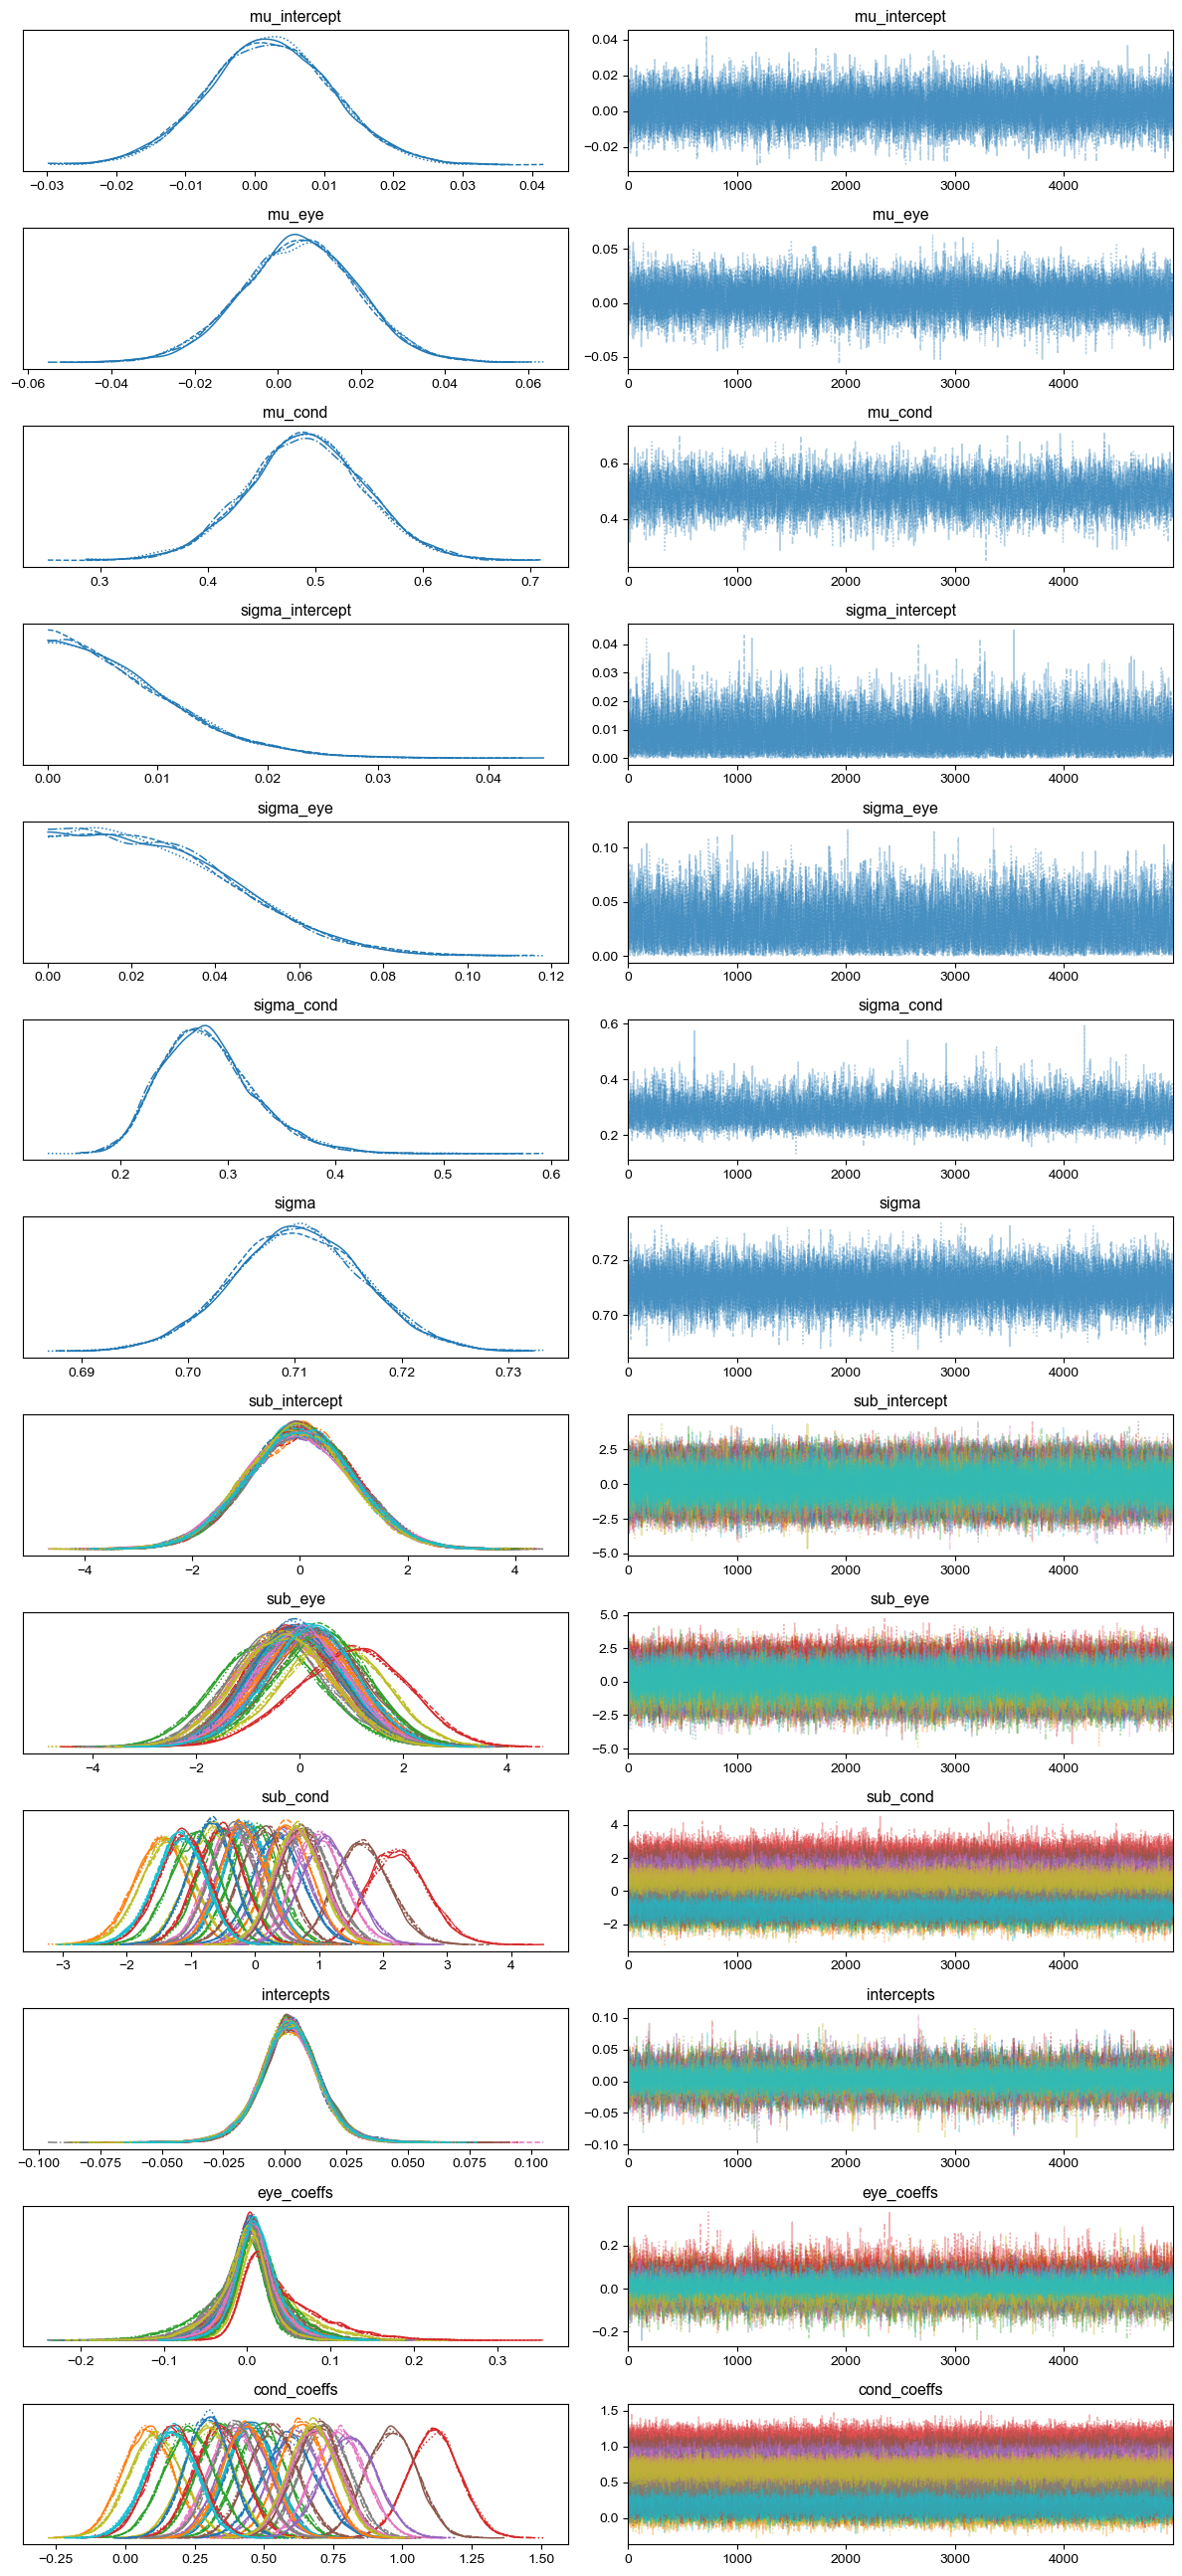

In [21]:
_ = pm.plot_trace(
    trace,
    var_names=[
        "mu_intercept",
        "mu_eye",
        "mu_cond",
        "sigma_intercept",
        "sigma_eye",
        "sigma_cond",
        "sigma",
        "sub_intercept",
        "sub_eye",
        "sub_cond",
        "intercepts",
        "eye_coeffs",
        "cond_coeffs",
    ],
)
plt.tight_layout()
plt.show()
plt.close()

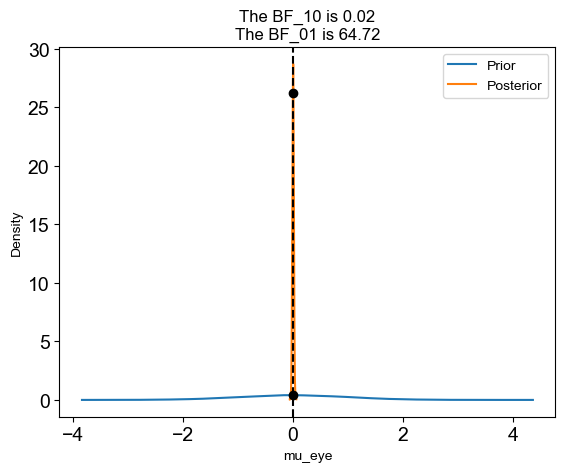

In [22]:
bf, fig = az.plot_bf(trace, var_name="mu_eye", ref_val=0)
plt.show()
plt.close()

The reference value is outside of the posterior. This translate into infinite support for H1, which is most likely an overstatement.


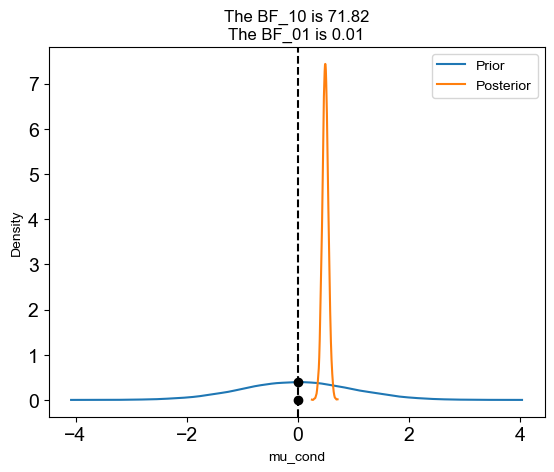

In [23]:
bf, fig = az.plot_bf(trace, var_name="mu_cond", ref_val=0)
plt.show()
plt.close()

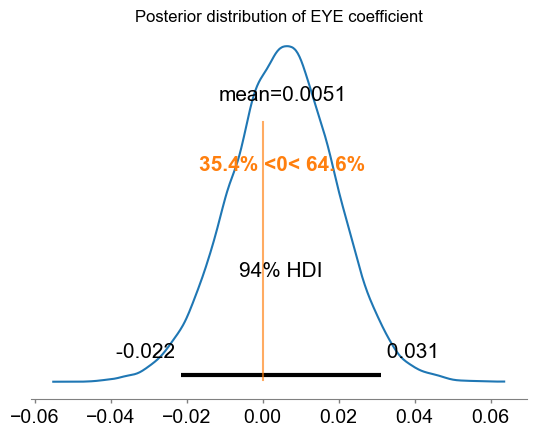

In [24]:
mu_eye_samples = trace.posterior["mu_eye"].values.flatten()
az.plot_posterior(mu_eye_samples, ref_val=0)
plt.title("Posterior distribution of EYE coefficient")
plt.show()
plt.close()

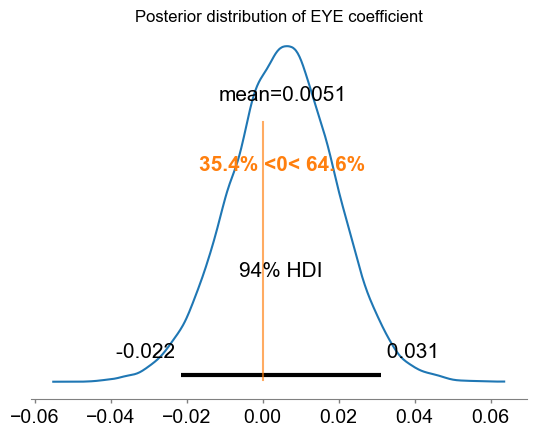

In [25]:
mu_eye_samples = trace.posterior["mu_eye"].values.flatten()
az.plot_posterior(mu_eye_samples, ref_val=0)
plt.title("Posterior distribution of EYE coefficient")
plt.show()
plt.close()

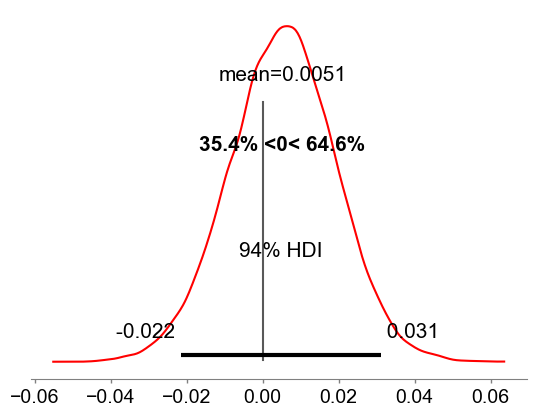

In [26]:
mu_eye_samples = trace.posterior["mu_eye"].values.flatten()
az.plot_posterior(mu_eye_samples, ref_val=0, ref_val_color="k", color="blue" if "A" in RUN_DESCRIPTION else "red")
plt.title("")
plt.savefig(f"figures/eye_param_posterior_desc-{RUN_DESCRIPTION}.png", bbox_inches="tight", transparent=True, dpi=300)
plt.show()
plt.close()

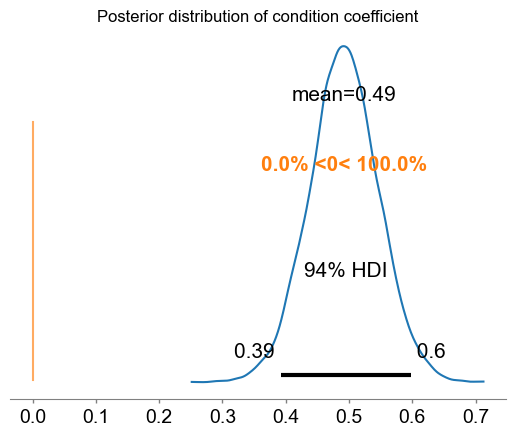

In [27]:
mu_cond_samples = trace.posterior["mu_cond"].values.flatten()
az.plot_posterior(mu_cond_samples, ref_val=0)
plt.title("Posterior distribution of condition coefficient")
plt.show()
plt.close()

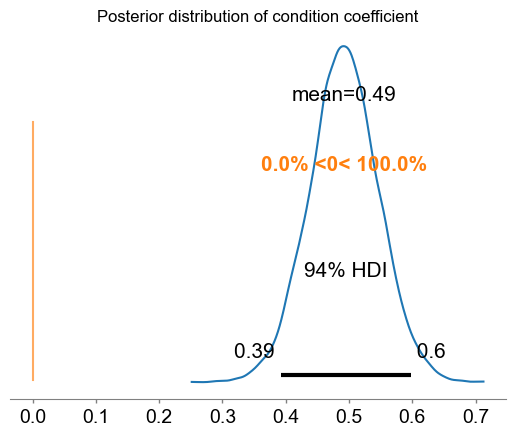

In [28]:
mu_cond_samples = trace.posterior["mu_cond"].values.flatten()
az.plot_posterior(mu_cond_samples, ref_val=0)
plt.title("Posterior distribution of condition coefficient")
plt.show()
plt.close()

# Rerun the at each timepoint

In [29]:
def pipeline(t):
    # 1. Build up dataframe of predictions at a given timepoint
    preds_df = pd.DataFrame()
    for isub in range(len(preds_perTrial)):
        sub_preds = preds_perTrial[isub]
        sub_preds_EYES = preds_EYES_perTrial[isub]
        sub_conds = conds[isub]
        cond_mask = np.isin(sub_conds, train_codes)
        # subset to training conditions only, since we're only interested in MI between conditions making up the contrast, for now,
        # average across iterations, and then across the delay period
        sub_preds = sub_preds[cond_mask][:, t]
        sub_preds_EYES = sub_preds_EYES[cond_mask][:, t]
        sub_conds = sub_conds[cond_mask]

        sub_df = pd.DataFrame({"EEG": sub_preds, "EYE": sub_preds_EYES, "cond": rescale_conds(sub_conds)})
        sub_df["sub"] = isub
        preds_df = pd.concat([preds_df, sub_df], ignore_index=True)

    preds_df["cond"] -= 0.5  # rescale conditions to be between -0.5 and 0.5, for better interpretability in modeling

    # 2. Build the model
    model = build_model(preds_df, eye_col="EYE")

    # 3. Sample from the posterior (& prior predictive)
    with model:
        trace = pm.sample(
            5000,  # real samples per chain
            tune=4000,  # warmup samples per chain
            chains=4,
            random_seed=0,
            target_accept=0.95,
            return_inferencedata=True,
            idata_kwargs={"log_likelihood": True},
            nuts_sampler="numpyro",
        )
        trace.extend(pm.sample_prior_predictive(20_000))  # add prior predictive samples to the idata for later checks

    # 4. Confirm convergence and summarize results
    summary_table = az.summary(trace)

    # 5. get the bayes factors
    cond_bf, _ = az.plot_bf(trace, var_name="mu_cond", ref_val=0)
    plt.close()

    eye_bf, _ = az.plot_bf(trace, var_name="mu_eye", ref_val=0)
    plt.close()

    return summary_table, cond_bf, eye_bf


In [30]:
if OVERWRITE or not path.exists(f"model_comparison_eyes/summary_table_desc-{RUN_DESCRIPTION}_t-0_model-EYES.csv"):
    summary_tables = []
    cond_bfs = []
    eye_bfs = []
    for t in tqdm(range(len(times))):
        summary_table, cond_bf, eye_bf = pipeline(t)
        summary_tables.append(summary_table)
        cond_bfs.append(cond_bf)
        eye_bfs.append(eye_bf)

    # save the summary tables and bayes factors for later analysis
    for t, summary_table in enumerate(summary_tables):
        summary_table.to_csv(f"model_comparison_eyes/summary_table_desc-{RUN_DESCRIPTION}_t-{t}_model-EYES.csv")

    with open(f"model_comparison_eyes/bayes_factors_desc-{RUN_DESCRIPTION}_factor-condition_model-EYES.json", "w") as f:
        json.dump(cond_bfs, f)

    with open(f"model_comparison_eyes/bayes_factors_desc-{RUN_DESCRIPTION}_factor-eye_model-EYES.json", "w") as f:
        json.dump(eye_bfs, f)
else:
    # load the summary tables and bayes factors for later analysis
    summary_tables = []
    cond_bfs = []
    eye_bfs = []
    for t in tqdm(range(len(times))):
        summary_table = pd.read_csv(f"model_comparison_eyes/summary_table_desc-{RUN_DESCRIPTION}_t-{t}_model-EYES.csv", index_col=0)
        summary_tables.append(summary_table)

    with open(f"model_comparison_eyes/bayes_factors_desc-{RUN_DESCRIPTION}_factor-condition_model-EYES.json", "r") as f:
        cond_bfs = json.load(f)

    with open(f"model_comparison_eyes/bayes_factors_desc-{RUN_DESCRIPTION}_factor-eye_model-EYES.json", "r") as f:
        eye_bfs = json.load(f)

  0%|          | 0/63 [00:00<?, ?it/s]

In [31]:
min_ess = min([summary_table.loc[["mu_eye", "mu_cond"]].ess_bulk.min() for summary_table in summary_tables])
max_rhat = max([summary_table.r_hat.max() for summary_table in summary_tables])
min_ess, max_rhat

(3638.0, 1.0)

In [32]:
cond_bfs_across_time = np.array([bfd["BF10"] for bfd in cond_bfs])
eye_bfs_across_time = np.array([bfd["BF10"] for bfd in eye_bfs])
bf_df = pd.DataFrame({"time": times, "cond_bf": cond_bfs_across_time, "eye_bf": eye_bfs_across_time})
bf_df["Log(BF10) Condition"] = np.log10(bf_df["cond_bf"])
bf_df["Log(BF10) Eye Scores"] = np.log10(bf_df["eye_bf"])

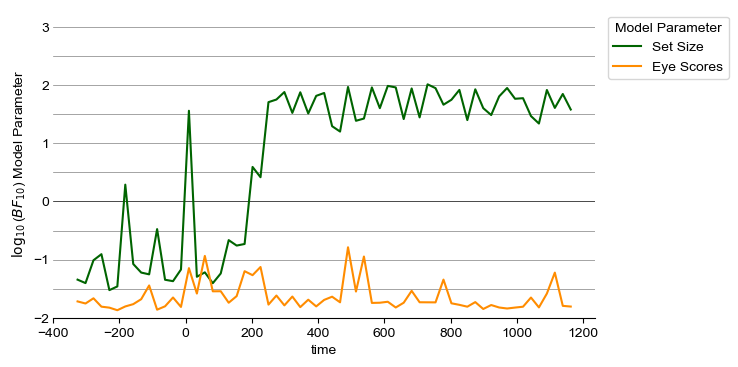

In [33]:
plt.figure(figsize=(7, 4))
sns.lineplot(data=bf_df, x="time", y="Log(BF10) Condition", label="Set Size", color="darkgreen")
ax = sns.lineplot(data=bf_df, x="time", y="Log(BF10) Eye Scores", label="Eye Scores", color="darkorange")
# add grid lines at Log10(1/10), Log10(1/5), Log10(1/3), Log10(1), Log10(3), Log10(5), Log10(10)

for i in range(6, -4, -1):
    if i == 0:
        plt.axhline(i, color="k", linestyle="-", linewidth=0.5, zorder=-1)
    else:
        plt.axhline(i/2, color="gray", linestyle="-", linewidth=0.5, zorder=-1)

plt.legend(title="Model Parameter", bbox_to_anchor=(1.01, 1), loc="upper left")
sns.despine()
plt.gca().spines["left"].set_visible(False)
plt.gca().yaxis.set_ticks_position("none")
plt.gca().yaxis.set_tick_params(pad=-1)
plt.ylim(-2, 3.3)
plt.yticks([-2, -1, 0, 1, 2, 3])
_ = plt.ylabel(r"$\log_{10}$($BF_{10}$) Model Parameter")
plt.savefig(f"figures/bayes_factors_desc-{RUN_DESCRIPTION}_model-EYES.png", bbox_inches="tight", transparent=True, dpi=300)
plt.show()
plt.close()

# Repeat everything now using the classifier scores based on pupils!

In [34]:
interp = mvEEG.Interpreter(
    data_dir=ROOT,
    experiment_name=EXPERIMENT_NAME,
    descriptions=[RUN_DESCRIPTION],
    labels=[0, 1],
    trial_phases={"Stim": (0, 200)},
    key_set=["predsPerTrialPUPIL"]
)

preds_PUPIL_perTrial = interp.dataset.get_data(
    None, keys=["predsPerTrialPUPIL"]
)

del interp  # free up memory, since we don't need it anymore

/Users/henryjones/Documents/research/banyan/Experiment 2/analyses/mvEEG/mvEEG/dataloader.py:101: UserWarning: Data files have inconsistent shapes: [[1000 1289   63]
 [1000 1331   63]
 [1000 1339   63]
 [1000 1364   63]
 [1000 1389   63]
 [1000 1434   63]
 [1000 1440   63]
 [1000 1450   63]
 [1000 1465   63]
 [1000 1470   63]
 [1000 1474   63]
 [1000 1492   63]
 [1000 1493   63]
 [1000 1495   63]
 [1000 1508   63]
 [1000 1511   63]
 [1000 1529   63]
 [1000 1531   63]
 [1000 1549   63]
 [1000 1567   63]
 [1000 1570   63]
 [1000 1574   63]
 [1000 1575   63]
 [1000 1580   63]
 [1000 1582   63]
 [1000 1587   63]
 [1000 1590   63]
 [1000 1595   63]
 [1000 1611   63]
 [1000 2202   63]]
  warnings.warn(f"Data files have inconsistent shapes: {shape}")


In [35]:
# mean across iterations
preds_PUPIL_perTrial_meaned = [p.mean(0) for p in preds_PUPIL_perTrial]
del preds_PUPIL_perTrial  # free up memory, since we don't need it anymore

preds_PUPIL_perTrial = preds_PUPIL_perTrial_meaned

In [36]:
preds_df = pd.DataFrame()
for isub in range(len(preds_perTrial)):
    sub_preds = preds_perTrial[isub]
    sub_preds_PUPIL = preds_PUPIL_perTrial[isub]
    sub_conds = conds[isub]
    cond_mask = np.isin(sub_conds, train_codes)
    # subset to training conditions only, since we're only interested in MI between conditions making up the contrast, for now,
    # average across iterations, and then across the delay period
    sub_preds = sub_preds[cond_mask][:, eeg_window].mean(1)
    sub_preds_PUPIL = sub_preds_PUPIL[cond_mask][:, pupil_window].mean(1)
    sub_conds = sub_conds[cond_mask]

    sub_df = pd.DataFrame({"EEG": sub_preds, "PUPIL": sub_preds_PUPIL, "cond": rescale_conds(sub_conds)})
    sub_df["sub"] = isub
    preds_df = pd.concat([preds_df, sub_df], ignore_index=True)

preds_df["cond"] -= 0.5  # rescale conditions to be between -0.5 and 0.5, for better interpretability in modeling

In [37]:
model = build_model(preds_df, eye_col="PUPIL")

In [38]:
with model:
    trace = pm.sample(
        5000,  # real samples per chain
        tune=4000,  # warmup samples per chain
        chains=4,
        random_seed=0,
        target_accept=0.95,
        return_inferencedata=True,
        idata_kwargs={"log_likelihood": True},
        nuts_sampler="numpyro",
    )
    trace.extend(pm.sample_prior_predictive(20_000))  # add prior predictive samples to the idata for later checks

  0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 0/9000 [00:00<?, ?it/s]

Sampling: [EEG_obs, mu_cond, mu_eye, mu_intercept, sigma, sigma_cond, sigma_eye, sigma_intercept, sub_cond, sub_eye, sub_intercept]


In [39]:
summary_table = az.summary(trace)
summary_table

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu_intercept,0.002,0.009,-0.015,0.019,0.000,0.000,38029.0,14871.0,1.0
mu_eye,0.024,0.013,-0.000,0.050,0.000,0.000,32847.0,15860.0,1.0
mu_cond,0.488,0.054,0.383,0.588,0.001,0.000,6687.0,9800.0,1.0
sub_intercept[0],0.026,0.974,-1.827,1.818,0.005,0.008,39725.0,14125.0,1.0
sub_intercept[1],0.020,0.986,-1.816,1.869,0.005,0.008,37845.0,14328.0,1.0
...,...,...,...,...,...,...,...,...,...
cond_coeffs[25],0.702,0.088,0.542,0.872,0.000,0.000,33474.0,15035.0,1.0
cond_coeffs[26],0.687,0.090,0.519,0.857,0.000,0.000,32907.0,14731.0,1.0
cond_coeffs[27],0.403,0.089,0.234,0.567,0.000,0.000,36074.0,14602.0,1.0
cond_coeffs[28],0.667,0.090,0.496,0.836,0.000,0.000,34897.0,15091.0,1.0


In [40]:
summary_table.loc[["mu_eye", "mu_cond"]]

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu_eye,0.024,0.013,-0.000,0.050,0.000,0.0,32847.0,15860.0,1.0
mu_cond,0.488,0.054,0.383,0.588,0.001,0.0,6687.0,9800.0,1.0


In [41]:
summary_table.ess_bulk.describe()

count      187.000000
mean     30309.893048
std       8657.040951
min       6112.000000
25%      27215.500000
50%      32137.000000
75%      36922.000000
max      42731.000000
Name: ess_bulk, dtype: float64

In [42]:
summary_table.r_hat.describe()

count    187.0
mean       1.0
std        0.0
min        1.0
25%        1.0
50%        1.0
75%        1.0
max        1.0
Name: r_hat, dtype: float64

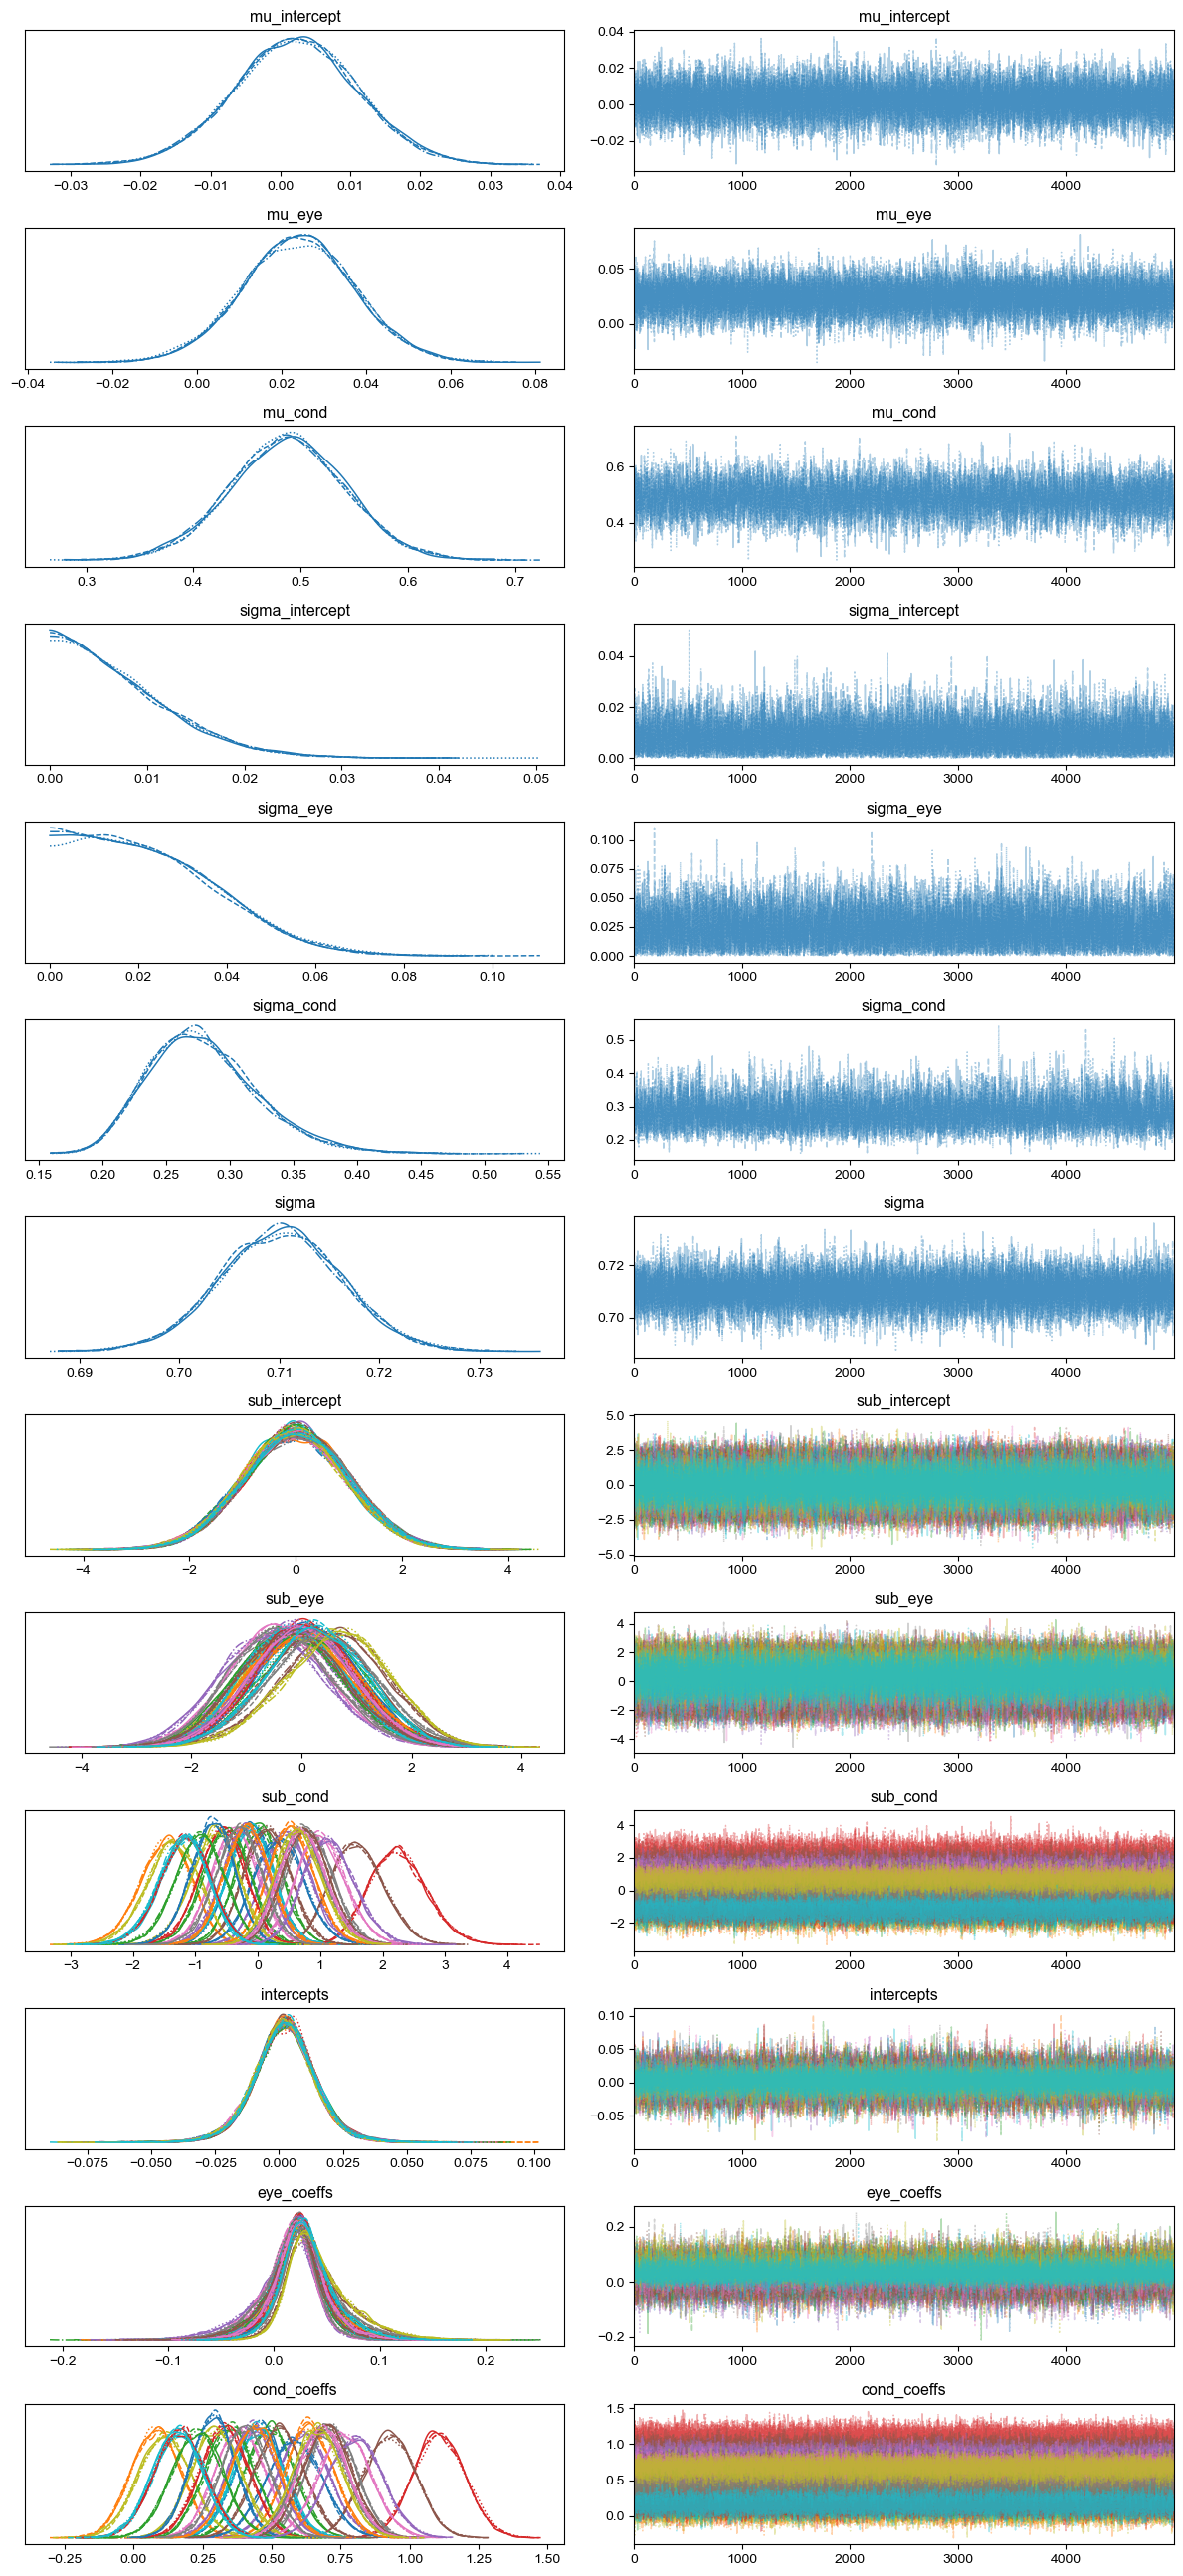

In [43]:
_ = pm.plot_trace(
    trace,
    var_names=[
        "mu_intercept",
        "mu_eye",
        "mu_cond",
        "sigma_intercept",
        "sigma_eye",
        "sigma_cond",
        "sigma",
        "sub_intercept",
        "sub_eye",
        "sub_cond",
        "intercepts",
        "eye_coeffs",
        "cond_coeffs",
    ],
)
plt.tight_layout()
plt.show()
plt.close()

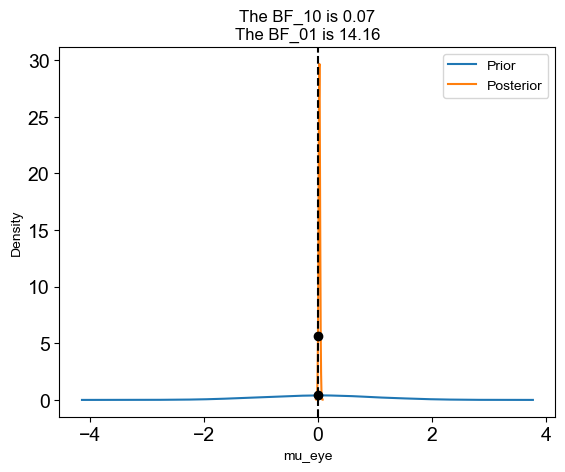

In [44]:
bf, fig = az.plot_bf(trace, var_name="mu_eye", ref_val=0)
plt.show()
plt.close()

The reference value is outside of the posterior. This translate into infinite support for H1, which is most likely an overstatement.


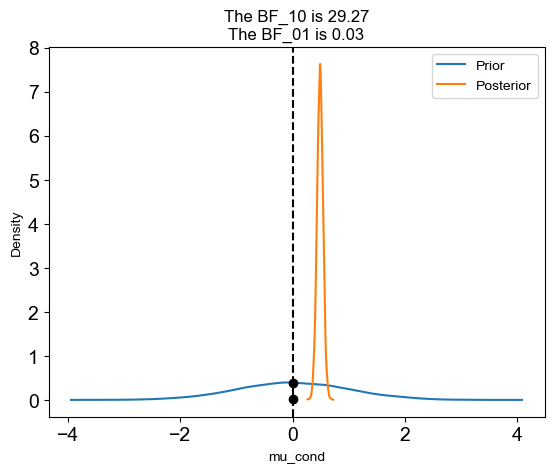

In [45]:
bf, fig = az.plot_bf(trace, var_name="mu_cond", ref_val=0)
plt.show()
plt.close()

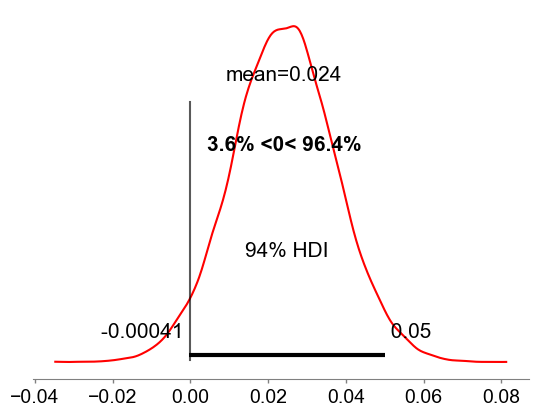

In [46]:
mu_eye_samples = trace.posterior["mu_eye"].values.flatten()
az.plot_posterior(mu_eye_samples, ref_val=0, ref_val_color="k", color="blue" if "A" in RUN_DESCRIPTION else "red")
plt.title("")
plt.show()
plt.close()

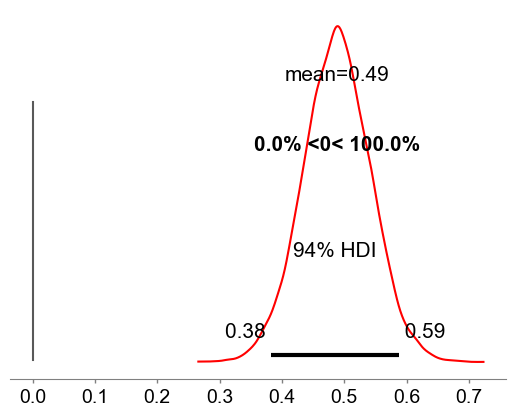

In [47]:
mu_eye_samples = trace.posterior["mu_cond"].values.flatten()
az.plot_posterior(mu_eye_samples, ref_val=0, ref_val_color="k", color="blue" if "A" in RUN_DESCRIPTION else "red")
plt.title("")
plt.show()
plt.close()

In [48]:
def pipeline_pupil(t):
    # 1. Build up dataframe of predictions at a given timepoint
    preds_df = pd.DataFrame()
    for isub in range(len(preds_perTrial)):
        sub_preds = preds_perTrial[isub]
        sub_preds_PUPIL = preds_PUPIL_perTrial[isub]
        sub_conds = conds[isub]
        cond_mask = np.isin(sub_conds, train_codes)
        # subset to training conditions only, since we're only interested in MI between conditions making up the contrast, for now,
        # average across iterations, and then across the delay period
        sub_preds = sub_preds[cond_mask][:, t]
        sub_preds_PUPIL = sub_preds_PUPIL[cond_mask][:, t]
        sub_conds = sub_conds[cond_mask]

        sub_df = pd.DataFrame({"EEG": sub_preds, "PUPIL": sub_preds_PUPIL, "cond": rescale_conds(sub_conds)})
        sub_df["sub"] = isub
        preds_df = pd.concat([preds_df, sub_df], ignore_index=True)

    preds_df["cond"] -= 0.5  # rescale conditions to be between -0.5 and 0.5, for better interpretability in modeling

    # 2. Build the model
    model = build_model(preds_df, eye_col="PUPIL")

    # 3. Sample from the posterior (& prior predictive)
    with model:
        trace = pm.sample(
            5000,  # real samples per chain
            tune=4000,  # warmup samples per chain
            chains=4,
            random_seed=0,
            target_accept=0.95,
            return_inferencedata=True,
            idata_kwargs={"log_likelihood": True},
            nuts_sampler="numpyro",
        )
        trace.extend(pm.sample_prior_predictive(20_000))  # add prior predictive samples to the idata for later checks

    # 4. Confirm convergence and summarize results
    summary_table = az.summary(trace)

    # 5. get the bayes factors
    cond_bf, _ = az.plot_bf(trace, var_name="mu_cond", ref_val=0)
    plt.close()

    eye_bf, _ = az.plot_bf(trace, var_name="mu_eye", ref_val=0)
    plt.close()

    return summary_table, cond_bf, eye_bf


In [49]:
if OVERWRITE or not path.exists(f"model_comparison_eyes/summary_table_desc-{RUN_DESCRIPTION}_t-0_model-pupil.csv"):
    summary_tables = []
    cond_bfs = []
    eye_bfs = []
    for t in tqdm(range(len(times))):
        summary_table, cond_bf, eye_bf = pipeline_pupil(t)
        summary_tables.append(summary_table)
        cond_bfs.append(cond_bf)
        eye_bfs.append(eye_bf)

    # save the summary tables and bayes factors for later analysis
    for t, summary_table in enumerate(summary_tables):
        summary_table.to_csv(f"model_comparison_eyes/summary_table_desc-{RUN_DESCRIPTION}_t-{t}_model-pupil.csv")

    with open(f"model_comparison_eyes/bayes_factors_desc-{RUN_DESCRIPTION}_factor-condition_model-pupil.json", "w") as f:
        json.dump(cond_bfs, f)

    with open(f"model_comparison_eyes/bayes_factors_desc-{RUN_DESCRIPTION}_factor-eye_model-pupil.json", "w") as f:
        json.dump(eye_bfs, f)
else:
    # load the summary tables and bayes factors for later analysis
    summary_tables = []
    cond_bfs = []
    eye_bfs = []
    for t in tqdm(range(len(times))):
        summary_table = pd.read_csv(f"model_comparison_eyes/summary_table_desc-{RUN_DESCRIPTION}_t-{t}_model-pupil.csv", index_col=0)
        summary_tables.append(summary_table)

    with open(f"model_comparison_eyes/bayes_factors_desc-{RUN_DESCRIPTION}_factor-condition_model-pupil.json", "r") as f:
        cond_bfs = json.load(f)

    with open(f"model_comparison_eyes/bayes_factors_desc-{RUN_DESCRIPTION}_factor-eye_model-pupil.json", "r") as f:
        eye_bfs = json.load(f)

  0%|          | 0/63 [00:00<?, ?it/s]

In [50]:
min_ess = min([summary_table.loc[["mu_eye", "mu_cond"]].ess_bulk.min() for summary_table in summary_tables])
max_rhat = max([summary_table.r_hat.max() for summary_table in summary_tables])
min_ess, max_rhat

(4144.0, 1.0)

In [51]:
cond_bfs_across_time = np.array([bfd["BF10"] for bfd in cond_bfs])
eye_bfs_across_time = np.array([bfd["BF10"] for bfd in eye_bfs])
bf_df = pd.DataFrame({"time": times, "cond_bf": cond_bfs_across_time, "eye_bf": eye_bfs_across_time})
bf_df["Log(BF10) Condition"] = np.log10(bf_df["cond_bf"])
bf_df["Log(BF10) Eye Scores"] = np.log10(bf_df["eye_bf"])

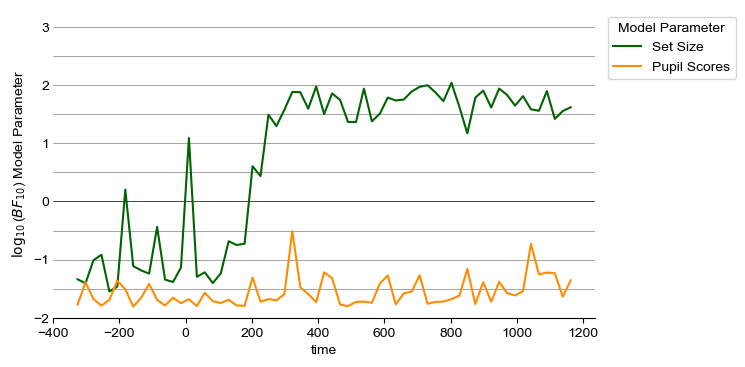

In [52]:
plt.figure(figsize=(7, 4))
sns.lineplot(data=bf_df, x="time", y="Log(BF10) Condition", label="Set Size", color="darkgreen")
ax = sns.lineplot(data=bf_df, x="time", y="Log(BF10) Eye Scores", label="Pupil Scores", color="darkorange")
for i in range(6, -4, -1):
    if i == 0:
        plt.axhline(i, color="k", linestyle="-", linewidth=0.5, zorder=-1)
    else:
        plt.axhline(i/2, color="gray", linestyle="-", linewidth=0.5, zorder=-1)

plt.legend(title="Model Parameter", bbox_to_anchor=(1.01, 1), loc="upper left")
sns.despine()
plt.gca().spines["left"].set_visible(False)
plt.gca().yaxis.set_ticks_position("none")
plt.gca().yaxis.set_tick_params(pad=-1)
plt.ylim(-2, 3.3)
plt.yticks([-2, -1, 0, 1, 2, 3])
_ = plt.ylabel(r"$\log_{10}$($BF_{10}$) Model Parameter")
plt.savefig(f"figures/bayes_factors_desc-{RUN_DESCRIPTION}_model-Pupil.png", bbox_inches="tight", transparent=True, dpi=300)
plt.show()
plt.close()